# Week 6: Python analysis: what explains the payment gap?

**The one question.** For a comparable mix of stays, why does Medicare pay some hospitals more than others? And of that gap, how much reflects real differences between hospitals, and how much is Medicare paying more by design?

**The approach: before vs after.** Two regressions on log(payment_index), the same 2,476 hospitals in each, OLS with robust (HC3) standard errors.

- BEFORE: star rating, ownership, urban/rural and Census region (R-squared 0.27).
- AFTER: the same groups plus the three things Medicare deliberately pays more for: the FY 2024 wage index, teaching (residents per bed) and the DSH share of low-income patients, all from the FY 2024 IPPS impact file (R-squared 0.69).
- Comparing the two: the region gaps (mostly; Northeast flips to -3.5%) and nearly all the star-rating gaps are accounted for by the added variables. The ownership gaps shrink but hold. Rural flips sign and comes out paid more. The 27 hospitals with very high residuals, flagged with the same IQR rule as Week 4, become the outside-research list.

**The tests.** H1 to H4 as simple statistics, each with a 95% bootstrap CI:

- H1 states: 39% of the variation is between states, 61% within (Kruskal-Wallis p near 0).
- H2 rating and ownership: only a weak link to star rating (Spearman rho -0.08); ownership is the clearer split, government about 3% above typical and for-profit about 6% below.
- H3 markup: median markup 4.2x. For-profit hospitals bill the most (6.6x) yet are paid the least; government is the reverse, so list prices and what Medicare pays move slightly in opposite directions (Spearman rho -0.15).
- H4 urban vs rural: no clear evidence the typical urban hospital is paid more (Mann-Whitney p = 0.06); the average urban premium of 5.7% comes mainly from a minority of big-city hospitals.
- Supporting checks: scatter plots with a Spearman correlation for each factor; k-means with k = 3 (best silhouette, 0.519) groups hospitals into Typical, High-wage and Teaching; residual plots, low VIF (1.1 to 1.25) and a discharge-weighted WLS rerun (R-squared 0.81) back up the AFTER model. In the weighted rerun the government and rural premiums roughly halve (+5.4% to +2.8%, +8.5% to +3.9%), so they sit mostly in smaller hospitals.

**Sources.** The Gold tables as before: workspace.cms.gold_hospital_index (2,862 non-Maryland hospitals), gold_dim_hospital_profile (2,906), gold_fact_inpatient (145,879) and gold_hospital_drg_deviation (145,878), plus the FY 2024 IPPS Final Rule Impact File (3,199 hospitals) for the wage, teaching and DSH factors. The analysis frame holds 2,493 hospitals.

**The exports.** Two Delta tables, workspace.cms.gold_python_hospital_results (one row per hospital, 2,493 rows x 28 columns) and workspace.cms.gold_python_before_after (the group-by-group comparison); three CSVs in /Volumes/workspace/cms/exports/ (hospital_results.csv, before_after.csv, and research_list.csv with the 27 hospitals for next week's outside research); and the slide charts saved as PNGs. Everything is ready for Tableau.

In [0]:
%python
# Install statsmodels (used for regression and diagnostics)
%pip install statsmodels

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
%python
# 0. Setup: imports (pandas, numpy, scipy.stats, statsmodels.formula.api, statsmodels.stats.outliers_influence), display options, random seed

import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt

# Display options: show every column, 4 decimal places
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.4f}".format)

# Random seed for any later sampling or bootstrap 
np.random.seed(42)

In [0]:
# 1. Load Gold tables into pandas: gold_hospital_index, gold_dim_hospital_profile, gold_fact_inpatient, gold_hospital_drg_deviation
#    Checks: 2,862 / 2,906 / 145,879 / 145,878 rows; ccn unique in gold_hospital_index and gold_dim_hospital_profile

# Load each Delta table into pandas DataFrame
hospital_index = spark.table("workspace.cms.gold_hospital_index").toPandas()
profile = spark.table("workspace.cms.gold_dim_hospital_profile").toPandas()
fact = spark.table("workspace.cms.gold_fact_inpatient").toPandas()
deviation = spark.table("workspace.cms.gold_hospital_drg_deviation").toPandas()

# Row counts: print them, then assert so the cell fails loudly if anything changed
print("hospital_index:", len(hospital_index))
print("profile:", len(profile))
print("fact:", len(fact))
print("deviation:", len(deviation))

assert len(hospital_index) == 2862, "gold_hospital_index row count changed"
assert len(profile) == 2906, "gold_dim_hospital_profile row count changed"
assert len(fact) == 145879, "gold_fact_inpatient row count changed"
assert len(deviation) == 145878, "gold_hospital_drg_deviation row count changed"

# ccn must be unique in the two one-row-per-hospital tables
assert hospital_index["ccn"].is_unique, "duplicate ccn in gold_hospital_index"
assert profile["ccn"].is_unique, "duplicate ccn in gold_dim_hospital_profile"

# Quick look at column names and types
print(hospital_index.dtypes)
print(profile.dtypes)

hospital_index: 2862
profile: 2906
fact: 145879
deviation: 145878
ccn                     object
state_abbr              object
provider_city           object
provider_name           object
urban_rural             object
census_region           object
n_drgs                   int64
is_low_drg_hospital       bool
tot_discharges           int64
tot_payment             object
expected_payment       float64
payment_index          float64
n_outlier_cells          int64
share_outlier_cells    float64
q1                     float64
q3                     float64
is_hospital_outlier       bool
dtype: object
ccn                        object
hospital_type              object
hospital_ownership         object
ownership_group            object
has_emergency_services     object
star_rating               float64
rating_category            object
is_profile_matched           bool
dtype: object


In [0]:
# 1b. Convert DECIMAL columns to float: Spark DECIMAL arrives in pandas as Python Decimal objects (dtype object)
#     Checks: no object-typed money columns left in hospital_index or fact

# Find columns that should be numbers but came through as object
print(fact.dtypes)

# Convert the money columns to float
hospital_index["tot_payment"] = hospital_index["tot_payment"].astype(float)

money_cols = ["avg_submitted_charge", "avg_total_payment", "avg_medicare_payment","tot_submitted_charge", "tot_total_payment", "tot_medicare_payment"]

fact[money_cols] = fact[money_cols].astype(float)

deviation["avg_total_payment"] = deviation["avg_total_payment"].astype(float)
assert deviation["avg_total_payment"].dtype == "float64", "deviation avg_total_payment still not float"

# Check: none of the converted columns are object anymore
assert hospital_index["tot_payment"].dtype == "float64", "tot_payment still not float"
assert (fact[money_cols].dtypes == "float64").all(), "a fact money column is still not float"

print(deviation.dtypes)

ccn                      object
drg_cd                   object
tot_discharges            int32
avg_submitted_charge     object
avg_total_payment        object
avg_medicare_payment     object
tot_submitted_charge     object
tot_total_payment        object
tot_medicare_payment     object
markup_ratio            float64
dtype: object
ccn                    object
drg_cd                 object
avg_total_payment     float64
median_payment        float64
payment_ratio         float64
q1_payment            float64
q3_payment            float64
is_thin_drg              bool
is_payment_outlier       bool
dtype: object


In [0]:
# 2. Read the FY2024 IPPS impact file from /Volumes/workspace/cms/raw/: skip title line 1, header on line 2, tab-separated, Latin-1
#    Keep Provider Number (as 6-character ccn, leading zeros kept), FY 2024 Wage Index, Resident to Bed Ratio, DSHPCT
#    Checks: 3,199 rows x 59 columns; ccn unique and 6 characters; 2,891 of 2,906 inpatient hospitals match; no blanks in the three controls among matched

impact_path = "/Volumes/workspace/cms/raw/FY 2024 IPPS Final Rule Impact File.txt"

impact_raw = pd.read_csv(
    impact_path, 
    sep="\t", #tab-separated
    skiprows=1, #line 1 is a title, the header is on line 2, so skip line 1
    encoding="latin-1",
    dtype={"Provider Number": str}, # read the CCN as text so leading zeros survive 
)

print(impact_raw.shape)
assert impact_raw.shape == (3199, 59), "impact file shape changed"

# Keep 4 columns and rename them to snake_case (old name: new name)
keep = {
    "Provider Number": "ccn",
    "FY 2024 Wage Index": "wage_index",
    "Resident to Bed Ratio": "rbr",
    "DSHPCT": "dsh_pct",
}
impact = impact_raw[list(keep)].rename(columns=keep)

# Clean the key: strip spaces, pad to 6 characters
impact["ccn"] = impact["ccn"].str.strip().str.zfill(6)
assert impact["ccn"].is_unique, "duplicate ccn in impact file"
assert (impact["ccn"].str.len() == 6).all(), "ccn is not 6 characters"




(3199, 59)


In [0]:
# 2b. Match all inpatient CCNs before merging.
matched = profile["ccn"].isin(impact["ccn"])
print("Impact matches:", matched.sum(), "of", len(matched))
assert matched.sum() == 2891
# Keep the unmatched list as run evidence, not an exclusion by itself.
print(profile.loc[~matched, "ccn"].tolist())
controls = ["wage_index", "rbr", "dsh_pct"]
impact_matched = impact.loc[impact["ccn"].isin(profile["ccn"])]
print(impact_matched[controls].isna().sum())
assert impact_matched[controls].notna().all().all()
print(impact[controls].dtypes)

Impact matches: 2891 of 2906
['100362', '670333', '030154', '100364', '140310', '050854', '040164', '050855', '390339', '060133', '340195', '440238', '100363', '360374', '490147']
wage_index    0
rbr           0
dsh_pct       0
dtype: int64
wage_index    float64
rbr           float64
dsh_pct       float64
dtype: object


In [0]:
# 3. Analysis frame: one row per non-Maryland hospital with index, profile, IPPS factors and markup
#    Checks: 2,862 rows after merges (no fan-out); 2,493 after dropping low-DRG hospitals

# Hospital markup (H3): billed / paid, totals over totals across all of a hospital's DRGs
markup = (
    fact.groupby("ccn")[["tot_submitted_charge", "tot_total_payment"]]
        .sum()
        .reset_index()
)
markup["markup"] = markup["tot_submitted_charge"] / markup["tot_total_payment"]

# Profile columns needed for H2 and H3 (state_abbr already comes from hospital_index)
profile_cols = ["ccn", "ownership_group", "rating_category", "star_rating"]

# Start from hospital_index (non-Maryland, has payment_index), then left-join the rest on ccn
df = (
    hospital_index
        .merge(profile[profile_cols], on="ccn", how= "left")
        .merge(impact, on="ccn", how="left")
        .merge(markup[["ccn", "markup"]], on="ccn", how="left")
)
assert len(df) == 2862, "merge changed the row count (fan-out)"

# Exclusion: low-DRG hospitals (<5 DRGs, DQ-17) are not reliable enough for tests
analysis = df[~df["is_low_drg_hospital"]].copy()
print("analysis rows:", len(analysis))
assert len(analysis) == 2493, "expected 2,493 eligible hospitals"

# Missing values per column: each test drops only the rows it can't use
print(analysis[["rating_category", "ownership_group", "wage_index", "rbr", "dsh_pct", "markup"]].isna().sum())

# Group sizes the tests will use
print(analysis["urban_rural"].value_counts(dropna=False))
print(analysis["ownership_group"].value_counts(dropna=False))
print(analysis["rating_category"].value_counts(dropna=False))

analysis rows: 2493
rating_category    1
ownership_group    1
wage_index         4
rbr                4
dsh_pct            4
markup             0
dtype: int64
urban_rural
Urban      1899
Rural       582
Unknown      12
Name: count, dtype: int64
ownership_group
Non-profit    1679
For-profit     494
Government     319
None             1
Name: count, dtype: int64
rating_category
3          698
4          646
2          490
5          293
1          237
Unrated    128
None         1
Name: count, dtype: int64


2493 hospitals
count   2493.0000
mean       1.0643
std        0.3543
min        0.6061
25%        0.8894
50%        0.9882
75%        1.1398
max        9.9493
Name: payment_index, dtype: float64
median       0.988   95% CI 0.978 to 0.995
mean         1.064   95% CI 1.051 to 1.079
share > 1.0  0.471   95% CI 0.451 to 0.490


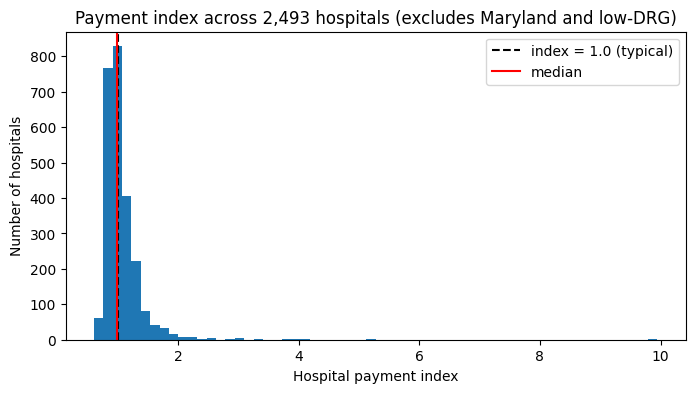

In [0]:
# 4. Payment index distribution: median, mean, share above 1.0, each with a 95% bootstrap CI
#    Checks: 2,493 values, no blanks; median near 1.0

idx = analysis["payment_index"].dropna()
print(len(idx), "hospitals")
print(idx.describe())

# Bootstrap: resample the hospitals with replacement many times, recompute the statistic each
# time, and take the middle 95% of those results as the confidence interval
def bootstrap_ci(values, stat_fn, n_boot=5000, seed=42):
    rng = np.random.default_rng(seed)
    values = np.asarray(values)
    boots = np.array([
        stat_fn(rng.choice(values, size=len(values), replace=True))
        for _ in range(n_boot)
    ])
    return np.percentile(boots, [2.5, 97.5])

# Share of hospitals paid above the typical price for their mix of stays (index > 1.0)
def share_above_one(v):
    return np.mean(v > 1.0)

for name, fn in [("median", np.median), ("mean", np.mean), ("share > 1.0", share_above_one)]:
    lo, hi = bootstrap_ci(idx, fn)
    print(f"{name:12s} {fn(idx):.3f}   95% CI {lo:.3f} to {hi:.3f}")

# Histogram: where most hospitals sit, and how long the right tail is
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(idx, bins=60)
ax.axvline(1.0, color="black", linestyle="--", label="index = 1.0 (typical)")
ax.axvline(np.median(idx), color="red", label="median")
ax.set_xlabel("Hospital payment index")
ax.set_ylabel("Number of hospitals")
ax.set_title("Payment index across 2,493 hospitals (excludes Maryland and low-DRG)")
ax.legend()
plt.show()

In [0]:
# 5. H1: how much of the variation in payment index is BETWEEN states vs WITHIN states
#    Method: split the variance of log(payment_index) into a between-state part and a
#    within-state part; between share = between / total (eta-squared), with a bootstrap CI.
#    Kruskal-Wallis tests whether states differ at all.
#    Checks: 50 states (Maryland excluded)

h1 = analysis[["state_abbr", "payment_index"]].dropna().copy()          # the state column and the index column
h1["log_index"] = np.log(h1["payment_index"])                    # log reduces the right skew from cell 4
print(h1["state_abbr"].nunique(), "states,", len(h1), "hospitals")

# Share of the total variation explained by which state a hospital is in
def between_share(frame, group_col="state_abbr", y="log_index"):
    grand = frame[y].mean()
    g = frame.groupby(group_col)[y]
    ss_between = (g.size() * (g.mean() - grand) ** 2).sum()   # how far state averages sit from the overall average
    ss_total = ((frame[y] - grand) ** 2).sum()                 # how far every hospital sits from the overall average
    return ss_between / ss_total

eta2 = between_share(h1)

# Bootstrap CI: resample hospitals 1,000 times and recompute the share
rng = np.random.default_rng(42)
boots = [between_share(h1.sample(frac=1, replace=True, random_state=int(rng.integers(1e9))))
         for _ in range(1000)]
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"between-state share {eta2:.1%}   95% CI {lo:.1%} to {hi:.1%}")
print(f"within-state share  {1 - eta2:.1%}")

# Kruskal-Wallis: are the states' index distributions different at all? (rank-based, no normality needed)
samples = [grp["payment_index"].values for _, grp in h1.groupby("state_abbr")]
H, p = stats.kruskal(*samples)
print(f"Kruskal-Wallis H = {H:.1f}, p = {p:.2g}")

# State medians for the slide: lowest 5 and highest 5
state_med = h1.groupby("state_abbr")["payment_index"].agg(["median", "count"]).sort_values("median")
print(state_med.head(5))
print(state_med.tail(5))

50 states, 2493 hospitals
between-state share 39.1%   95% CI 35.3% to 44.5%
within-state share  60.9%
Kruskal-Wallis H = 1075.1, p = 4.3e-193
            median  count
state_abbr               
VT          0.8046      6
AR          0.8251     34
LA          0.8339     47
AL          0.8646     46
IA          0.8674     27
            median  count
state_abbr               
CA          1.2826    242
DC          1.3880      6
HI          1.4353     11
WY          1.4509      8
AK          1.6739      7


In [0]:
# 6. H2: does the payment index differ by star rating or by ownership?
#    Method: group medians with 95% bootstrap CIs; Kruskal-Wallis across groups;
#    Spearman correlation between star_rating (1 to 5) and the index, with a bootstrap CI.
#    Checks: 1 hospital with no rating/ownership is dropped; "Unrated" stays its own group

def group_summary(frame, group_col, y="payment_index", n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    rows = []
    for name, grp in frame.groupby(group_col):
        v = grp[y].values
        boots = [np.median(rng.choice(v, size=len(v), replace=True)) for _ in range(n_boot)]
        lo, hi = np.percentile(boots, [2.5, 97.5])
        rows.append({group_col: name, "n": len(v), "median": np.median(v), "ci_low": lo, "ci_high": hi})
    return pd.DataFrame(rows)

def kruskal_by(frame, group_col, y="payment_index"):
    samples = [grp[y].values for _, grp in frame.groupby(group_col)]
    H, p = stats.kruskal(*samples)
    print(f"Kruskal-Wallis by {group_col}: H = {H:.1f}, p = {p:.2g}")

# --- Star rating (category, includes Unrated) ---
h2_rating = analysis[["rating_category", "payment_index"]].dropna()
print(group_summary(h2_rating, "rating_category"))
kruskal_by(h2_rating, "rating_category")

# Trend check: do more stars go with a lower or higher index? (rated hospitals only)
rated = analysis[["star_rating", "payment_index"]].dropna()
x = rated["star_rating"].to_numpy()
y = rated["payment_index"].to_numpy()
rho, p = stats.spearmanr(x, y)

# Faster bootstrap: draw all 1,000 resamples as row numbers at once, no DataFrame copies
rng = np.random.default_rng(42)
rows = rng.integers(0, len(x), size=(1000, len(x)))
boots = [stats.spearmanr(x[r], y[r])[0] for r in rows]
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"Spearman rho (stars vs index) = {rho:.3f}   95% CI {lo:.3f} to {hi:.3f}   p = {p:.2g}   n = {len(x)}")

# --- Ownership ---
h2_own = analysis[["ownership_group", "payment_index"]].dropna()
print(group_summary(h2_own, "ownership_group"))
kruskal_by(h2_own, "ownership_group")

  rating_category    n  median  ci_low  ci_high
0               1  237  1.0304  0.9941   1.0807
1               2  490  1.0119  0.9948   1.0323
2               3  698  0.9860  0.9757   1.0018
3               4  646  0.9566  0.9453   0.9692
4               5  293  1.0007  0.9723   1.0328
5         Unrated  128  0.9436  0.9097   1.0006
Kruskal-Wallis by rating_category: H = 38.4, p = 3.2e-07
Spearman rho (stars vs index) = -0.077   95% CI -0.117 to -0.037   p = 0.00018   n = 2364
  ownership_group     n  median  ci_low  ci_high
0      For-profit   494  0.9395  0.9212   0.9561
1      Government   319  1.0292  1.0056   1.0650
2      Non-profit  1679  0.9914  0.9817   1.0019
Kruskal-Wallis by ownership_group: H = 59.3, p = 1.3e-13


In [0]:
# 7. H3: does hospital markup (billed / paid) differ by group?
#    Markup = total billed charges / total Medicare payment per hospital (built in cell 3).
#    Method: overall median with bootstrap CI; group medians with CIs; Kruskal-Wallis.
#    Checks: no blanks in markup; every markup above 1 (hospitals bill more than they're paid)

mk = analysis[["ownership_group", "markup"]].dropna()          # grouped by ownership, as in the proposal's H3
print(len(mk), "hospitals")
print(mk["markup"].describe())
print("hospitals with markup below 1:", (mk["markup"] < 1).sum())

# Overall median markup with a bootstrap CI (bootstrap_ci is from cell 4)
lo, hi = bootstrap_ci(mk["markup"], np.median)
print(f"overall median markup {mk['markup'].median():.2f}   95% CI {lo:.2f} to {hi:.2f}")

# By group (functions from cell 6, with y set to markup)
print(group_summary(mk, "ownership_group", y="markup"))
kruskal_by(mk, "ownership_group", y="markup")

2492 hospitals
count   2492.0000
mean       4.8330
std        2.6290
min        0.3131
25%        3.1000
50%        4.1875
75%        5.7216
max       22.6801
Name: markup, dtype: float64
hospitals with markup below 1: 3
overall median markup 4.19   95% CI 4.10 to 4.27
  ownership_group     n  median  ci_low  ci_high
0      For-profit   494  6.6052  5.9448   7.0955
1      Government   319  3.3328  3.1046   3.5124
2      Non-profit  1679  4.0177  3.9262   4.1024
Kruskal-Wallis by ownership_group: H = 357.3, p = 2.6e-78


In [0]:
# 8. H4: are urban hospitals paid more than rural ones for the same mix of stays?
#    Method: median index by group with bootstrap CIs; ratio of mean index (urban / rural)
#    with a bootstrap CI; Mann-Whitney U test (two-group version of Kruskal-Wallis).
#    Checks: the 12 "Unknown" hospitals are dropped from this test only

h4 = analysis.loc[analysis["urban_rural"].isin(["Urban", "Rural"]), ["urban_rural", "payment_index"]]
print(h4["urban_rural"].value_counts())

print(group_summary(h4, "urban_rural"))

urban = h4.loc[h4["urban_rural"] == "Urban", "payment_index"].to_numpy()
rural = h4.loc[h4["urban_rural"] == "Rural", "payment_index"].to_numpy()

# Ratio of means: how much more (or less) urban hospitals are paid than rural, case-mix adjusted
ratio = urban.mean() / rural.mean()
rng = np.random.default_rng(42)
boots = [rng.choice(urban, len(urban)).mean() / rng.choice(rural, len(rural)).mean() for _ in range(5000)]
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"urban / rural mean index = {ratio:.3f}   95% CI {lo:.3f} to {hi:.3f}")

U, p = stats.mannwhitneyu(urban, rural, alternative="two-sided")
print(f"Mann-Whitney U = {U:.0f}, p = {p:.2g}")

urban_rural
Urban    1899
Rural     582
Name: count, dtype: int64
  urban_rural     n  median  ci_low  ci_high
0       Rural   582  0.9827  0.9662   0.9938
1       Urban  1899  0.9899  0.9778   0.9996
urban / rural mean index = 1.057   95% CI 1.032 to 1.082
Mann-Whitney U = 581013, p = 0.06


2489 hospitals


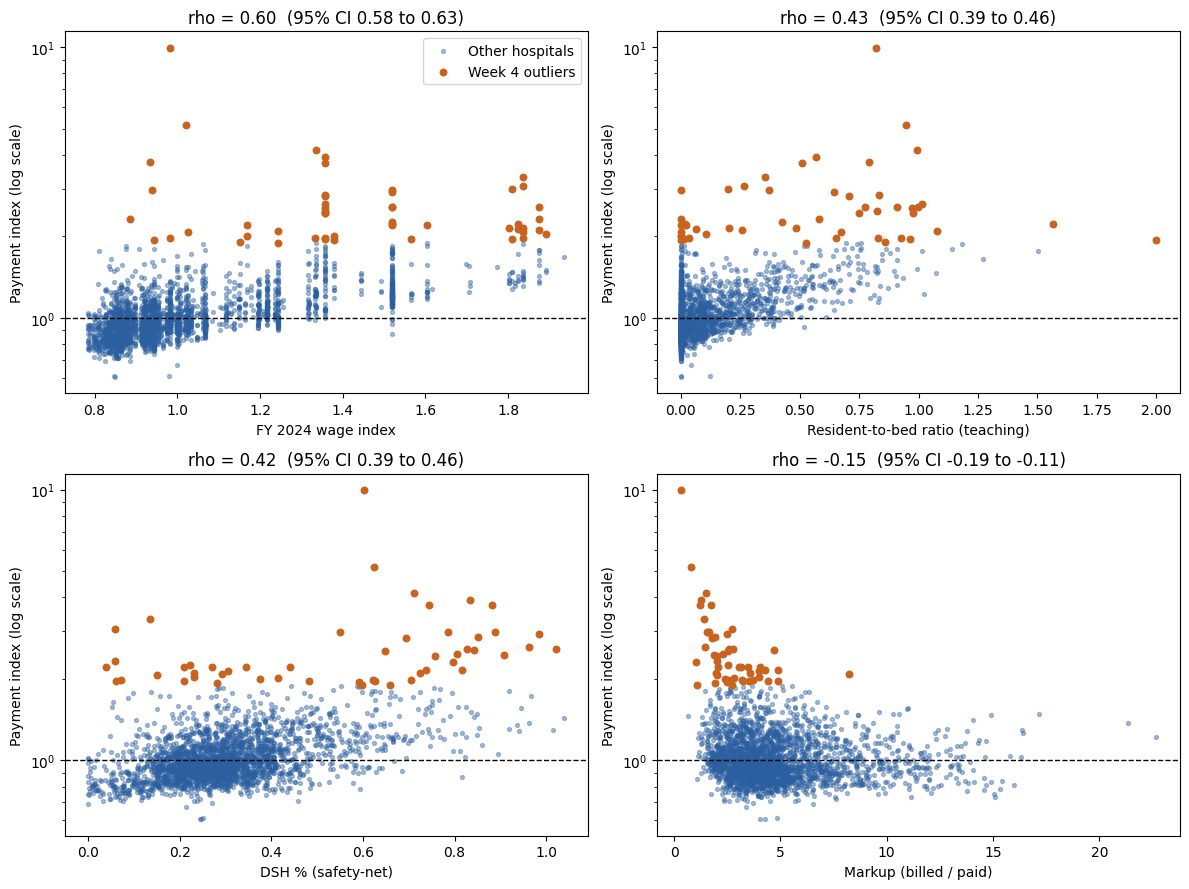

       factor     rho  ci_low  ci_high      p
0  wage_index  0.6030  0.5770   0.6310 0.0000
1         rbr  0.4270  0.3900   0.4580 0.0000
2     dsh_pct  0.4230  0.3880   0.4580 0.0000
3      markup -0.1480 -0.1850  -0.1110 0.0000
rbr = 0: 1341 of 2489


In [0]:
# 9. Scatter plots: payment index vs wage index, teaching (rbr), safety-net (DSH%), markup
#    Method: Spearman rank correlation for each, with a 95% bootstrap CI; log y-axis so the
#    tail doesn't flatten everything; the 51 Week 4 outlier hospitals highlighted.
#    Checks: 2,489 hospitals with all three IPPS factors (4 newly opened have none)

factors = {
    "wage_index":     "FY 2024 wage index",
    "rbr":     "Resident-to-bed ratio (teaching)",
    "dsh_pct":     "DSH % (safety-net)",
    "markup": "Markup (billed / paid)",
}
sc = analysis[["ccn", "payment_index", "is_hospital_outlier"] + list(factors)].dropna()
print(len(sc), "hospitals")

def spearman_ci(x, y, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    rows = rng.integers(0, len(x), size=(n_boot, len(x)))
    boots = [stats.spearmanr(x[r], y[r])[0] for r in rows]
    return np.percentile(boots, [2.5, 97.5])

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
results = []
for ax, (col, label) in zip(axes.ravel(), factors.items()):
    x = sc[col].to_numpy()
    y = sc["payment_index"].to_numpy()
    rho, p = stats.spearmanr(x, y)
    lo, hi = spearman_ci(x, y)
    results.append({"factor": col, "rho": rho, "ci_low": lo, "ci_high": hi, "p": p})

    out = sc["is_hospital_outlier"].to_numpy(dtype=bool)                   # the Week 4 outlier flag
    ax.scatter(x[~out], y[~out], s=8, alpha=0.4, color="#2B5FA0", label="Other hospitals")
    ax.scatter(x[out], y[out], s=22, color="#C8641F", label="Week 4 outliers")
    ax.set_yscale("log")
    ax.axhline(1.0, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel(label)
    ax.set_ylabel("Payment index (log scale)")
    ax.set_title(f"rho = {rho:.2f}  (95% CI {lo:.2f} to {hi:.2f})")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

print(pd.DataFrame(results).round(3))

# How many hospitals have no teaching at all (rbr = 0)? Matters for reading the teaching plot
print("rbr = 0:", (sc["rbr"] == 0).sum(), "of", len(sc))

In [0]:
# 10a. BEFORE Medicare's adjustments: do groups of hospitals get paid differently
#      for the same mix of stays?
#      Model: log(payment_index) ~ star rating + ownership + urban/rural + region
#      OLS with HC3 robust standard errors (honest CIs even when spread differs by group).
#      The same hospitals are reused in 10b (AFTER), so the two can be compared directly.
#      Sample: drops Unknown urban/rural (12), the 1 unmatched hospital, the 4 with no IPPS factors

reg_cols = ["ccn", "provider_name", "state_abbr", "payment_index", "tot_discharges", "is_hospital_outlier",
            "rating_category", "ownership_group", "urban_rural", "census_region",
            "wage_index", "rbr", "dsh_pct"]
reg = analysis.loc[analysis["urban_rural"] != "Unknown", reg_cols].dropna().copy()
reg["log_index"] = np.log(reg["payment_index"])
reg["rating_category"] = reg["rating_category"].astype(str)     # so "3" and "Unrated" are the same type
print(len(reg), "hospitals in both models")
print(reg["rating_category"].unique())
print(reg["census_region"].value_counts())

# Comparison groups: every gap is measured AGAINST these (chosen: the middle rating and the largest group of each)
ref_rating = 3       # middle rating
ref_own    = "Non-profit"       # largest ownership group
ref_urban  = "Urban"
ref_region = "South"       # largest region in the counts above

groups = (
    f"C(rating_category, Treatment(reference='{ref_rating}'))"
    f" + C(ownership_group, Treatment(reference='{ref_own}'))"
    f" + C(urban_rural, Treatment(reference='{ref_urban}'))"
    f" + C(census_region, Treatment(reference='{ref_region}'))"
)
before = smf.ols(f"log_index ~ {groups}", data=reg).fit(cov_type="HC3")

# Readable table: on a log outcome, exp(coef) - 1 = % paid above (+) or below (-) the comparison group
def pct_table(model):
    ci = model.conf_int()
    t = pd.DataFrame({
        "pct_diff": (np.exp(model.params) - 1) * 100,
        "ci_low":   (np.exp(ci[0]) - 1) * 100,
        "ci_high":  (np.exp(ci[1]) - 1) * 100,
        "p":        model.pvalues,
    }).drop("Intercept")
    t.index = (t.index.str.replace(r"C\((\w+), Treatment\(reference='[^']*'\)\)\[T\.", r"\1: ", regex=True)
                      .str.replace("]", "", regex=False))
    return t.round({"pct_diff": 1, "ci_low": 1, "ci_high": 1, "p": 4})

print(f"BEFORE adjustments: n = {int(before.nobs)}, R-squared = {before.rsquared:.3f}, "
      f"adj. R-squared = {before.rsquared_adj:.3f}")
print(pct_table(before))

2476 hospitals in both models
['1' '2' '3' '4' '5' 'Unrated']
census_region
South        957
Midwest      604
West         506
Northeast    409
Name: count, dtype: int64
BEFORE adjustments: n = 2476, R-squared = 0.267, adj. R-squared = 0.263
                             pct_diff  ci_low  ci_high      p
rating_category: 1             7.2000  3.5000  11.0000 0.0001
rating_category: 2             2.1000 -0.4000   4.5000 0.0954
rating_category: 4            -2.9000 -4.8000  -1.0000 0.0025
rating_category: 5            -0.5000 -3.0000   2.1000 0.6964
rating_category: Unrated      -3.8000 -7.4000   0.0000 0.0518
ownership_group: For-profit   -5.4000 -7.0000  -3.7000 0.0000
ownership_group: Government   11.7000  7.7000  15.8000 0.0000
urban_rural: Rural            -0.9000 -2.6000   0.9000 0.3267
census_region: Midwest         4.0000  2.1000   5.9000 0.0000
census_region: Northeast      19.9000 16.8000  23.1000 0.0000
census_region: West           29.4000 26.4000  32.4000 0.0000


In [0]:
# 10b. AFTER Medicare's adjustments: are the gaps from 10a still there once the model accounts for
#      the three things Medicare deliberately pays more for (local wages, teaching, low-income patients)?
#      Same hospitals and comparison groups as 10a; adds wage index, teaching ratio and DSH share.
#      The three factors are rescaled so each % reads per a sensible step (see comments).

reg["wage_step"] = reg["wage_index"] / 0.1     # per 0.1 higher wage index
reg["rbr_step"]  = reg["rbr"] / 0.1            # per 0.1 more residents per bed
reg["dsh_step"]  = reg["dsh_pct"] / 0.1        # per 10 percentage points more low-income patients

after = smf.ols(f"log_index ~ {groups} + wage_step + rbr_step + dsh_step", data=reg).fit(cov_type="HC3")

print(f"AFTER adjustments:  n = {int(after.nobs)}, R-squared = {after.rsquared:.3f}, "
      f"adj. R-squared = {after.rsquared_adj:.3f}")
print(f"BEFORE (from 10a):  R-squared = {before.rsquared:.3f}")
print(pct_table(after))

# Side by side: how much of each group gap is left after Medicare's adjustments?
t_before, t_after = pct_table(before), pct_table(after)
compare = pd.DataFrame({
    "before_pct": t_before["pct_diff"],
    "after_pct":  t_after.loc[t_before.index, "pct_diff"],
    "after_ci_low":  t_after.loc[t_before.index, "ci_low"],
    "after_ci_high": t_after.loc[t_before.index, "ci_high"],
})
compare["share_left"] = (compare["after_pct"] / compare["before_pct"]).round(2)   # 1 = gap unchanged, 0 = fully explained
print(compare)

AFTER adjustments:  n = 2476, R-squared = 0.694, adj. R-squared = 0.692
BEFORE (from 10a):  R-squared = 0.267
                             pct_diff  ci_low  ci_high      p
rating_category: 1            -0.1000 -2.2000   1.9000 0.9028
rating_category: 2             0.6000 -1.0000   2.2000 0.4554
rating_category: 4             0.5000 -0.7000   1.8000 0.4110
rating_category: 5             1.7000  0.1000   3.4000 0.0393
rating_category: Unrated       1.7000 -1.5000   4.9000 0.3020
ownership_group: For-profit   -3.4000 -4.5000  -2.3000 0.0000
ownership_group: Government    5.4000  3.1000   7.8000 0.0000
urban_rural: Rural             8.5000  7.1000  10.0000 0.0000
census_region: Midwest        -1.0000 -2.3000   0.3000 0.1158
census_region: Northeast      -3.5000 -5.4000  -1.5000 0.0006
census_region: West            0.0000 -2.2000   2.3000 0.9976
wage_step                      5.6000  5.1000   6.0000 0.0000
rbr_step                       5.8000  5.2000   6.3000 0.0000
dsh_step              

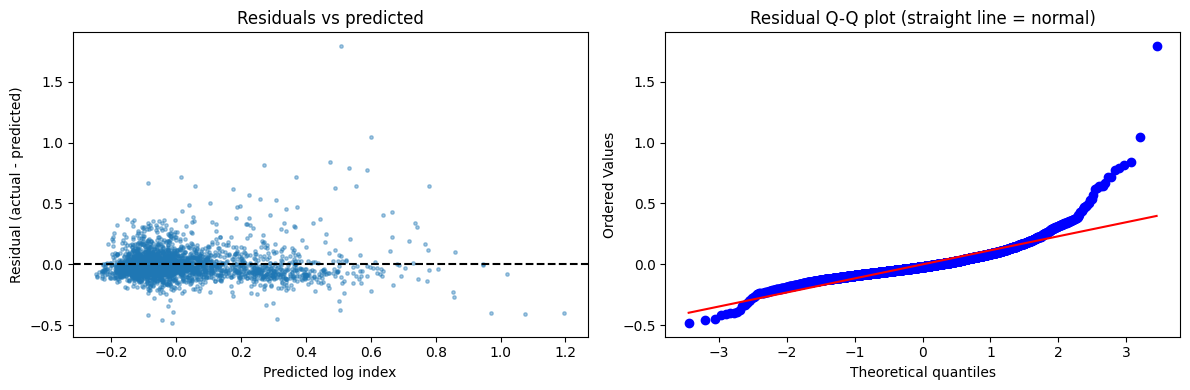

VIF:
 wage_index   1.1200
rbr          1.1300
dsh_pct      1.2500
dtype: float64
WLS R-squared = 0.812
                             OLS_after  WLS_after
rating_category: 1             -0.1000    -1.0000
rating_category: 2              0.6000    -0.8000
rating_category: 4              0.5000     0.1000
rating_category: 5              1.7000     1.6000
rating_category: Unrated        1.7000     1.5000
ownership_group: For-profit    -3.4000    -3.1000
ownership_group: Government     5.4000     2.8000
urban_rural: Rural              8.5000     3.9000
census_region: Midwest         -1.0000    -2.1000
census_region: Northeast       -3.5000    -3.7000
census_region: West             0.0000    -2.1000
wage_step                       5.6000     5.2000
rbr_step                        5.8000     5.3000
dsh_step                        2.2000     2.7000


In [0]:
# 10c. How reliable is the AFTER model?
#      (1) Residual plots: are the misses roughly centered on 0 with no strong pattern?
#      (2) VIF: are wage, teaching and DSH so tangled together that their effects can't be separated?
#      (3) Weighted check (WLS): do the results hold if big hospitals count more?

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# (1) Residuals = actual log index minus what the model predicts
reg["fitted_after"] = after.fittedvalues
reg["resid_after"]  = after.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(reg["fitted_after"], reg["resid_after"], s=6, alpha=0.4)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_xlabel("Predicted log index")
axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title("Residuals vs predicted")
stats.probplot(reg["resid_after"], dist="norm", plot=axes[1])
axes[1].set_title("Residual Q-Q plot (straight line = normal)")
plt.tight_layout()
plt.show()

# (2) VIF on the three Medicare factors (rule of thumb: above 5 is a worry, above 10 is a problem)
X = sm.add_constant(reg[["wage_index", "rbr", "dsh_pct"]])
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=X.columns[1:])
print("VIF:\n", vif.round(2))

# (3) Weighted check: weight each hospital by its number of discharges
wls = smf.wls(f"log_index ~ {groups} + wage_step + rbr_step + dsh_step",
              data=reg, weights=reg["tot_discharges"]).fit(cov_type="HC3")
check = pd.DataFrame({"OLS_after": pct_table(after)["pct_diff"], "WLS_after": pct_table(wls)["pct_diff"]})
print(f"WLS R-squared = {wls.rsquared:.3f}")
print(check)

In [0]:
# 10d. Who is left over? Hospitals paid far more than the AFTER model predicts for a hospital
#      with their rating, ownership, location, wage, teaching and DSH.
#      Flag rule (chosen): same IQR rule as Week 4 / DQ-14 for consistency, residual above Q3 + 3 x IQR.

# Residual back on a % scale: how much more (or less) the hospital is paid than predicted
reg["pct_above_predicted"] = (np.exp(reg["resid_after"]) - 1) * 100
reg["predicted_index"] = np.exp(reg["fitted_after"])

# Outlier threshold on the residuals
q1, q3 = reg["resid_after"].quantile([0.25, 0.75])
threshold = q3 + 3 * (q3 - q1)
reg["is_resid_outlier"] = reg["resid_after"] > threshold
print(f"Q1 {q1:.3f}, Q3 {q3:.3f}, threshold {threshold:.3f} (= {(np.exp(threshold)-1)*100:.0f}% above predicted)")
print("flagged:", reg["is_resid_outlier"].sum(), "of", len(reg))

# How do they line up with the 51 Week 4 outliers (flagged on the raw index, before any adjustment)?
print(pd.crosstab(reg["is_hospital_outlier"], reg["is_resid_outlier"],
                  rownames=["Week 4 outlier"], colnames=["Left over after adjustments"]))

# Who are they? Largest first
cols = ["provider_name", "state_abbr", "ownership_group", "urban_rural", "payment_index",
        "predicted_index", "pct_above_predicted", "wage_index", "rbr", "dsh_pct", "tot_discharges"]
left_over = reg.loc[reg["is_resid_outlier"], cols].sort_values("pct_above_predicted", ascending=False)
print(left_over.round(2).to_string())

# What kinds of hospitals are they?
print(left_over["ownership_group"].value_counts())
print(left_over["urban_rural"].value_counts())

Q1 -0.069, Q3 0.048, threshold 0.397 (= 49% above predicted)
flagged: 27 of 2476
Left over after adjustments  False  True 
Week 4 outlier                           
False                         2421      4
True                            28     23
                                         provider_name state_abbr ownership_group urban_rural  payment_index  predicted_index  pct_above_predicted  wage_index    rbr  dsh_pct  tot_discharges
509                                      Harris Health         TX      Government       Urban         9.9500           1.6600             499.3300      0.9800 0.8200   0.6000             254
545                         John H Stroger Jr Hospital         IL      Government       Urban         5.1700           1.8200             183.7100      1.0200 0.9500   0.6200             318
2414                            Queens Hospital Center         NY      Non-profit       Urban         3.7400           1.6100             132.2000      1.3600 0.5100   0.7400    

In [0]:
# 11. Clusters: group hospitals by their profile on the three Medicare factors
#     (wage index, teaching, DSH), then compare payment index and outliers across clusters.
#     Method: k-means on standardized factors; silhouette score used to choose k (k = 3 chosen).
#     Clustering uses only the factors, NOT the payment index, so the index can be compared afterwards.

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

feat = ["wage_index", "rbr", "dsh_pct"]
Z = StandardScaler().fit_transform(reg[feat])        # put all three on the same scale (mean 0, sd 1)

# Try k = 2 to 6: higher silhouette = cleaner separation between clusters
for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(Z)
    print(k, "clusters: silhouette", round(silhouette_score(Z, labels), 3))

k = 3                                              # chosen from the silhouette scores above
km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Z)
reg["cluster"] = km.labels_

# Describe each cluster: its typical factor values, payment index, and how many outliers it holds
profile_k = reg.groupby("cluster").agg(
    hospitals=("ccn", "size"),
    wage_index=("wage_index", "median"),
    rbr=("rbr", "median"),
    dsh_pct=("dsh_pct", "median"),
    median_index=("payment_index", "median"),
    week4_outliers=("is_hospital_outlier", "sum"),
    left_over=("is_resid_outlier", "sum"),
)
print(profile_k.round(3))

# Who is in each cluster (counts by ownership and urban/rural)
print(pd.crosstab(reg["cluster"], reg["ownership_group"]))
print(pd.crosstab(reg["cluster"], reg["urban_rural"]))

2 clusters: silhouette 0.511
3 clusters: silhouette 0.519
4 clusters: silhouette 0.289
5 clusters: silhouette 0.322
6 clusters: silhouette 0.318
         hospitals  wage_index    rbr  dsh_pct  median_index  week4_outliers  left_over
cluster                                                                                
0             1886      0.9330 0.0000   0.2600        0.9390               3          7
1              346      1.5190 0.0000   0.4000        1.2460              19         11
2              244      1.0330 0.5440   0.4200        1.3430              29          9
ownership_group  For-profit  Government  Non-profit
cluster                                            
0                       384         227        1275
1                        80          35         231
2                        28          53         163
urban_rural  Rural  Urban
cluster                  
0              536   1350
1               38    308
2                8    236


In [0]:
# 12. Export for Tableau: one row per hospital with everything the dashboard needs,
#     plus the before/after comparison table. Saved as Delta tables (Databricks) and CSVs (Tableau).

cluster_names = {0: "Typical", 1: "High-wage", 2: "Teaching"}     # names match the cell 11 profile table
reg["cluster_name"] = reg["cluster"].map(cluster_names)

# Add the hospitals that are in the analysis frame but not in the models (Unknown urban/rural, missing factors),
# so Tableau still shows all 2,493 on maps and distributions
model_cols = ["ccn", "predicted_index", "pct_above_predicted", "is_resid_outlier", "cluster_name"]
hospital_out = analysis.merge(reg[model_cols], on="ccn", how= "left")
assert len(hospital_out) == 2493, "export should have one row per hospital in the analysis frame"
print(hospital_out.shape)

# Before/after comparison (10a vs 10b), one row per group
compare_out = compare.reset_index().rename(columns={"index": "group"})

# Save as Delta tables
spark.createDataFrame(hospital_out).write.mode("overwrite").option("overwriteSchema", "true") \
    .saveAsTable("workspace.cms.gold_python_hospital_results")
spark.createDataFrame(compare_out).write.mode("overwrite").option("overwriteSchema", "true") \
    .saveAsTable("workspace.cms.gold_python_before_after")

# Save as CSVs in a separate volume (keeps exports out of the raw landing zone)
spark.sql("CREATE VOLUME IF NOT EXISTS workspace.cms.exports")
hospital_out.to_csv("/Volumes/workspace/cms/exports/hospital_results.csv", index=False)
compare_out.to_csv("/Volumes/workspace/cms/exports/before_after.csv", index=False)
print("saved")

(2493, 28)
saved


In [0]:
# 13. Research list: the 27 hospitals paid far more than their profile predicts (10d),
#     saved with blank columns to fill in during next week's outside research.

research_cols = ["ccn", "provider_name", "state_abbr", "ownership_group", "urban_rural", "cluster_name", "payment_index", "predicted_index", "pct_above_predicted", "wage_index", "rbr", "dsh_pct", "tot_discharges", "is_hospital_outlier"]
research = reg.loc[reg["is_resid_outlier"], research_cols].sort_values("pct_above_predicted", ascending=False).round(3)
research["group"] = ""          # e.g. public safety-net / Kaiser (Medicare Advantage) / remote-rural
research["likely_reason"] = ""  # what the outside research finds
research["source"] = ""         # link to the source

print(len(research), "hospitals")
print(research["cluster_name"].value_counts())
research.to_csv("/Volumes/workspace/cms/exports/research_list.csv", index=False)
print("saved research_list.csv")

27 hospitals
cluster_name
High-wage    11
Teaching      9
Typical       7
Name: count, dtype: int64
saved research_list.csv


In [0]:
# 14. Figures for the slides: setup shared by cells 14a to 14j.
#     Every chart reuses numbers already computed in cells 3 to 13 (plotting only, no new analysis).
#     Each chart is saved as a PNG in /Volumes/workspace/cms/exports/figures and shown below its cell.
import os
fig_dir = "/Volumes/workspace/cms/exports/figures"
os.makedirs(fig_dir, exist_ok=True)
BLUE, ORANGE, GREY, INK = "#2B5FA0", "#C8641F", "#B9B1A2", "#1C2430"
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name): fig.savefig(f"{fig_dir}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

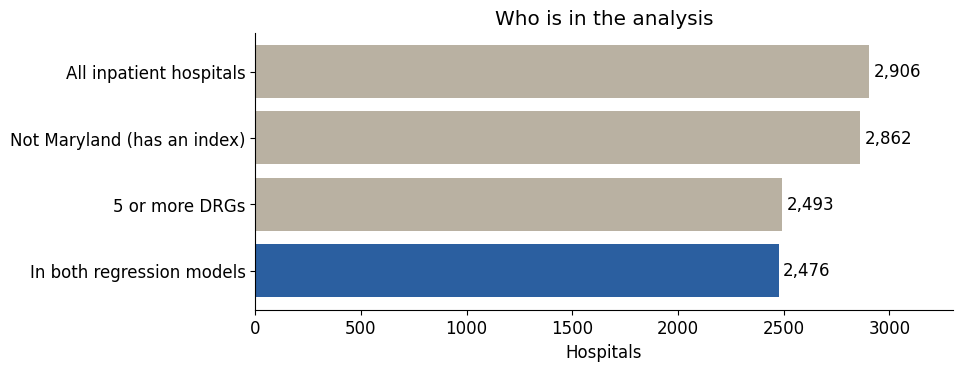

In [0]:
# 14a. Who is in the analysis (funnel)
#      Why this chart: the sample shrinks in three steps (Maryland, low-DRG, model sample), and a funnel
#      shows each exclusion and how many hospitals it removes at a glance, instead of a paragraph of rules.
steps = ["All inpatient hospitals", "Not Maryland (has an index)", "5 or more DRGs", "In both regression models"]
counts = [len(profile), len(hospital_index), len(analysis), len(reg)]
fig, ax = plt.subplots(figsize=(9, 3.6)); ax.barh(steps[::-1], counts[::-1], color=[BLUE, GREY, GREY, GREY])
[ax.text(c + 20, i, f"{c:,}", va="center") for i, c in enumerate(counts[::-1])]
ax.set_xlim(0, 3300); ax.set_xlabel("Hospitals"); ax.set_title("Who is in the analysis"); save(fig, "f01_sample_funnel")

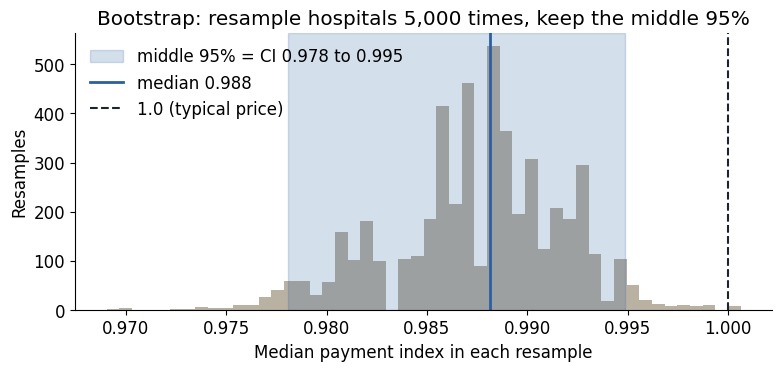

In [0]:
# 14b. What a 95% confidence interval is (bootstrap picture)
#      Why this chart: "CI" is abstract. Showing the 5,000 resampled medians and shading the middle 95%
#      shows exactly where the interval comes from, and that it sits just below 1.0.
rng = np.random.default_rng(42); vals = idx.to_numpy()
boot_med = np.median(rng.choice(vals, size=(5000, len(vals)), replace=True), axis=1)
lo, hi = np.percentile(boot_med, [2.5, 97.5])
fig, ax = plt.subplots(figsize=(9, 3.6)); ax.hist(boot_med, bins=50, color=GREY); ax.axvspan(lo, hi, color=BLUE, alpha=0.2, label=f"middle 95% = CI {lo:.3f} to {hi:.3f}")
ax.axvline(np.median(vals), color=BLUE, lw=2, label=f"median {np.median(vals):.3f}"); ax.axvline(1.0, color=INK, ls="--", label="1.0 (typical price)")
ax.set_xlabel("Median payment index in each resample"); ax.set_ylabel("Resamples"); ax.set_title("Bootstrap: resample hospitals 5,000 times, keep the middle 95%"); ax.legend(frameon=False); save(fig, "f02_bootstrap_ci")

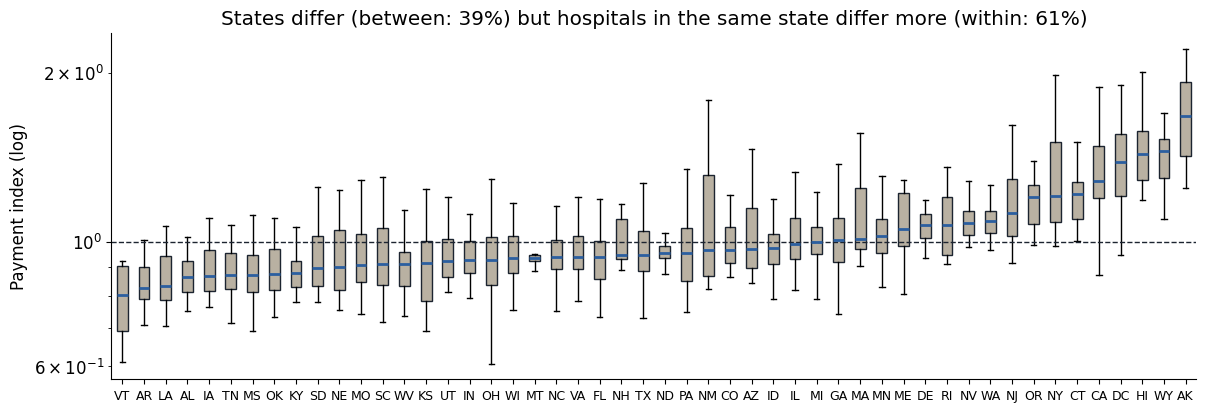

In [0]:
# 14c. H1: every state's hospitals, sorted by median
#      Why this chart: one box per state shows both parts of the variance split at once:
#      how far apart the boxes sit (between states) and how tall each box is (within a state).
order = h1.groupby("state_abbr")["payment_index"].median().sort_values().index
fig, ax = plt.subplots(figsize=(14, 4.5)); ax.boxplot([h1.loc[h1["state_abbr"] == s, "payment_index"] for s in order], tick_labels=order, showfliers=False, patch_artist=True, boxprops=dict(facecolor=GREY, color=INK), medianprops=dict(color=BLUE, lw=2))
ax.set_yscale("log"); ax.axhline(1.0, color=INK, ls="--", lw=1); ax.tick_params(axis="x", labelsize=9); ax.set_ylabel("Payment index (log)")
ax.set_title(f"States differ (between: {eta2:.0%}) but hospitals in the same state differ more (within: {1 - eta2:.0%})"); save(fig, "f03_h1_states")

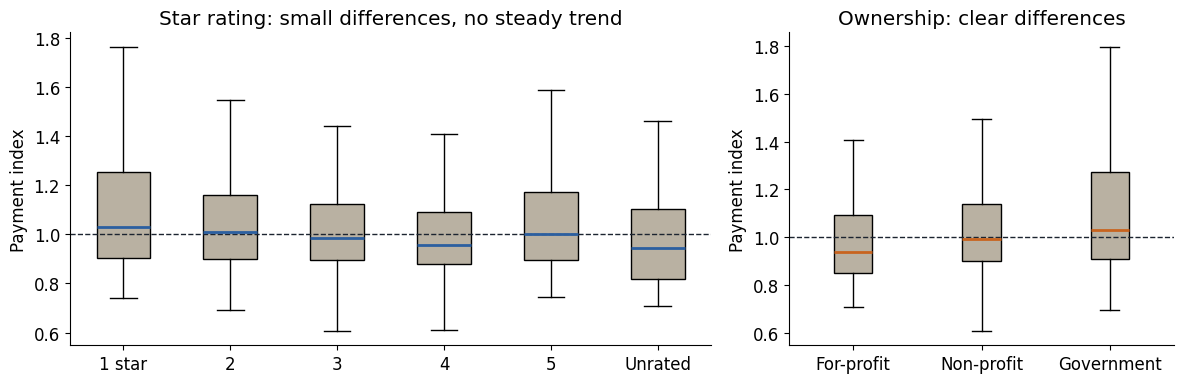

In [0]:
# 14d. H2: payment index by star rating and by ownership
#      Why this chart: boxplots show the whole spread, not just the median, so it is visible that
#      rating groups overlap heavily (small effect) while ownership groups are shifted (clearer effect).
rat_order = ["1", "2", "3", "4", "5", "Unrated"]; own_order = ["For-profit", "Non-profit", "Government"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1.2]})
axes[0].boxplot([h2_rating.loc[h2_rating["rating_category"].astype(str) == r, "payment_index"] for r in rat_order], tick_labels=["1 star", "2", "3", "4", "5", "Unrated"], showfliers=False, patch_artist=True, boxprops=dict(facecolor=GREY), medianprops=dict(color=BLUE, lw=2))
axes[1].boxplot([h2_own.loc[h2_own["ownership_group"] == o, "payment_index"] for o in own_order], tick_labels=own_order, showfliers=False, patch_artist=True, boxprops=dict(facecolor=GREY), medianprops=dict(color=ORANGE, lw=2))
[(a.axhline(1.0, color=INK, ls="--", lw=1), a.set_ylabel("Payment index")) for a in axes]
axes[0].set_title("Star rating: small differences, no steady trend"); axes[1].set_title("Ownership: clear differences"); fig.tight_layout(); save(fig, "f04_h2_rating_ownership")

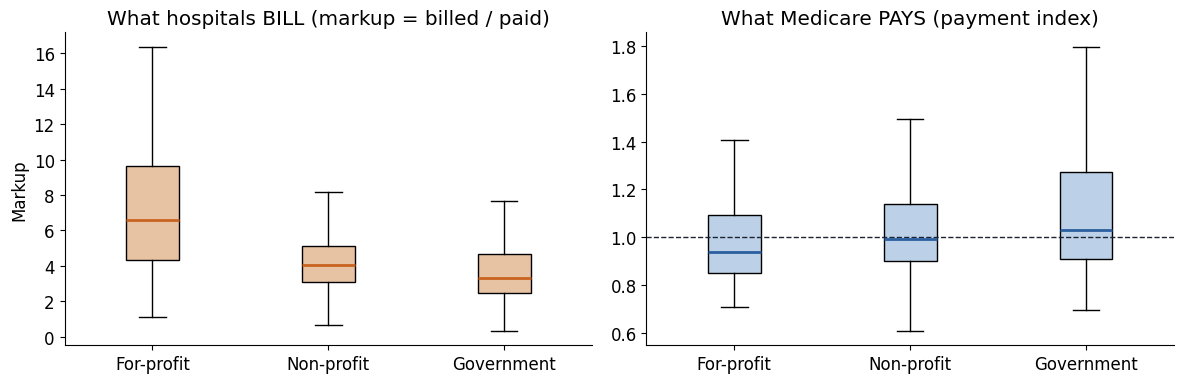

In [0]:
# 14e. H3: what hospitals bill vs what Medicare pays, by ownership
#      Why this chart: two panels side by side with the same groups make the opposite direction obvious:
#      for-profit highest on markup but lowest on payment, government the reverse.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot([mk.loc[mk["ownership_group"] == o, "markup"] for o in own_order], tick_labels=own_order, showfliers=False, patch_artist=True, boxprops=dict(facecolor="#E8C3A3"), medianprops=dict(color=ORANGE, lw=2)); axes[0].set_title("What hospitals BILL (markup = billed / paid)"); axes[0].set_ylabel("Markup")
axes[1].boxplot([h2_own.loc[h2_own["ownership_group"] == o, "payment_index"] for o in own_order], tick_labels=own_order, showfliers=False, patch_artist=True, boxprops=dict(facecolor="#BCD0E8"), medianprops=dict(color=BLUE, lw=2)); axes[1].set_title("What Medicare PAYS (payment index)"); axes[1].axhline(1.0, color=INK, ls="--", lw=1)
fig.tight_layout(); save(fig, "f05_h3_markup_vs_payment")

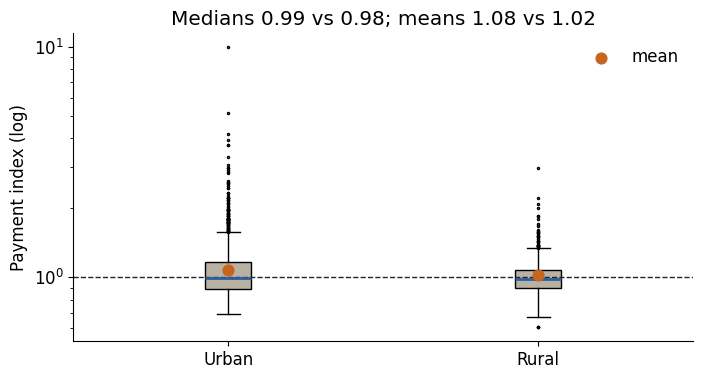

In [0]:
# 14f. H4: urban vs rural
#      Why this chart: the result hinges on median vs mean. Boxplots show the medians nearly equal, and the
#      orange mean dots plus the urban tail show why the average urban hospital still comes out higher.
fig, ax = plt.subplots(figsize=(8, 4)); grp = [h4.loc[h4["urban_rural"] == g, "payment_index"] for g in ["Urban", "Rural"]]
ax.boxplot(grp, tick_labels=["Urban", "Rural"], showfliers=True, flierprops=dict(marker=".", markersize=3, color=GREY), patch_artist=True, boxprops=dict(facecolor=GREY), medianprops=dict(color=BLUE, lw=2))
ax.scatter([1, 2], [g.mean() for g in grp], color=ORANGE, zorder=3, s=60, label="mean"); ax.set_yscale("log"); ax.axhline(1.0, color=INK, ls="--", lw=1); ax.legend(frameon=False)
ax.set_ylabel("Payment index (log)"); ax.set_title(f"Medians {np.median(grp[0]):.2f} vs {np.median(grp[1]):.2f}; means {grp[0].mean():.2f} vs {grp[1].mean():.2f}"); save(fig, "f06_h4_urban_rural")

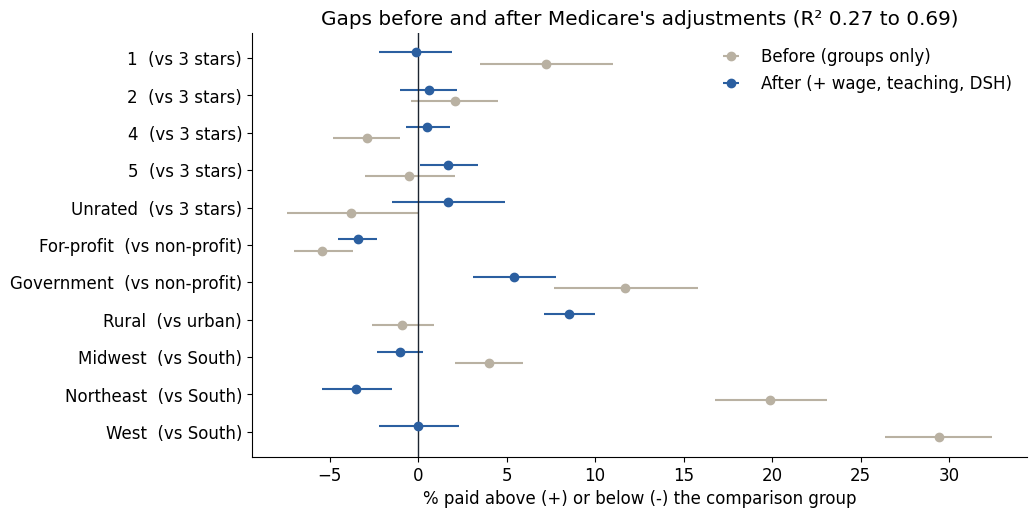

In [0]:
# 14g. Before vs after Medicare's adjustments (coefficient plot)
#      Why this chart: the core finding is how each group gap changes once wage, teaching and DSH are added.
#      Grey (before) and blue (after) dots with CI bars, side by side, show which gaps vanish and which remain.
tb, ta = pct_table(before), pct_table(after).loc[pct_table(before).index]; ypos = np.arange(len(tb))
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.errorbar(tb["pct_diff"], ypos + 0.15, xerr=[tb["pct_diff"] - tb["ci_low"], tb["ci_high"] - tb["pct_diff"]], fmt="o", color=GREY, label="Before (groups only)")
ax.errorbar(ta["pct_diff"], ypos - 0.15, xerr=[ta["pct_diff"] - ta["ci_low"], ta["ci_high"] - ta["pct_diff"]], fmt="o", color=BLUE, label="After (+ wage, teaching, DSH)")
ax.axvline(0, color=INK, lw=1); ax.set_yticks(ypos); ax.set_yticklabels([i.split(": ")[1] + "  (" + i.split(": ")[0].replace("_", " ").replace("rating category", "vs 3 stars").replace("ownership group", "vs non-profit").replace("urban rural", "vs urban").replace("census region", "vs South") + ")" for i in tb.index])
ax.invert_yaxis(); ax.set_xlabel("% paid above (+) or below (-) the comparison group"); ax.set_title(f"Gaps before and after Medicare's adjustments (R² {before.rsquared:.2f} to {after.rsquared:.2f})"); ax.legend(frameon=False, loc="upper right"); save(fig, "f07_before_after")

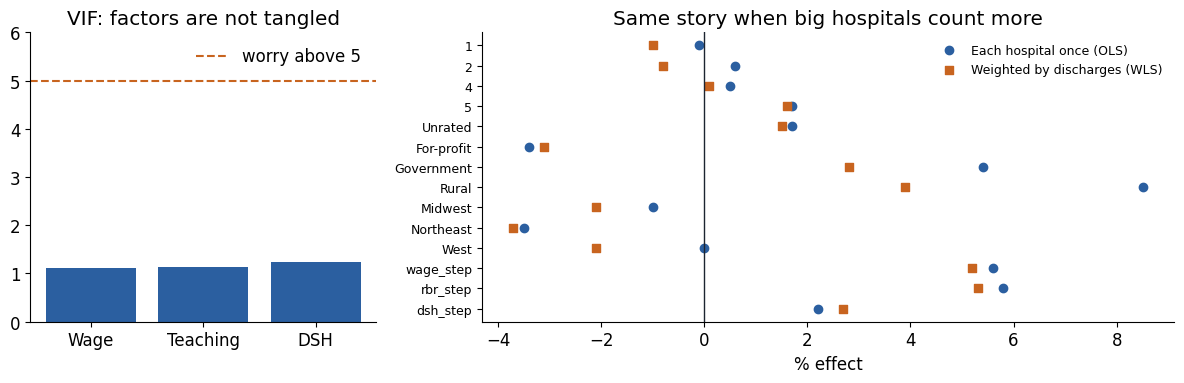

In [0]:
# 14h. Model checks: VIF and unweighted vs weighted estimates
#      Why this chart: bars against the "worry above 5" line show the factors are not tangled, and the
#      paired dots show which results hold when big hospitals count more (most) and which shrink (government, rural).
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})
axes[0].bar(["Wage", "Teaching", "DSH"], vif.values, color=BLUE); axes[0].axhline(5, color=ORANGE, ls="--", label="worry above 5"); axes[0].set_ylim(0, 6); axes[0].set_title("VIF: factors are not tangled"); axes[0].legend(frameon=False)
ck = check.copy(); yy = np.arange(len(ck)); axes[1].scatter(ck["OLS_after"], yy, color=BLUE, label="Each hospital once (OLS)"); axes[1].scatter(ck["WLS_after"], yy, color=ORANGE, marker="s", label="Weighted by discharges (WLS)")
axes[1].set_yticks(yy); axes[1].set_yticklabels([i.split(": ")[-1] for i in ck.index], fontsize=9); axes[1].axvline(0, color=INK, lw=1); axes[1].invert_yaxis(); axes[1].set_xlabel("% effect"); axes[1].set_title("Same story when big hospitals count more"); axes[1].legend(frameon=False, fontsize=9)
fig.tight_layout(); save(fig, "f08_model_checks")

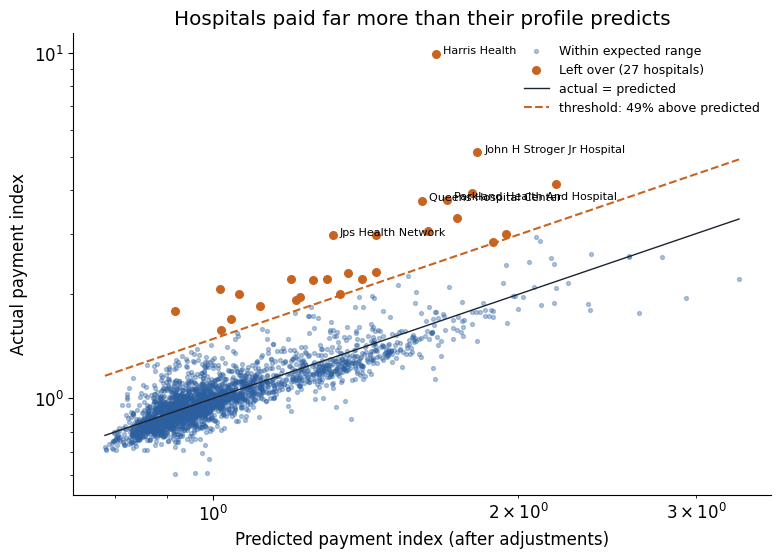

In [0]:
# 14i. Who is left over: actual vs predicted payment index
#      Why this chart: each dot is a hospital; the diagonal is "paid as predicted" and the dashed line is the
#      outlier threshold. Hospitals above the dashed line are the left-over list, with the top 5 named.
fig, ax = plt.subplots(figsize=(9, 6)); ok = ~reg["is_resid_outlier"]
ax.scatter(reg.loc[ok, "predicted_index"], reg.loc[ok, "payment_index"], s=8, alpha=0.35, color=BLUE, label="Within expected range")
ax.scatter(reg.loc[~ok, "predicted_index"], reg.loc[~ok, "payment_index"], s=30, color=ORANGE, label=f"Left over ({(~ok).sum()} hospitals)")
xs = np.linspace(reg["predicted_index"].min(), reg["predicted_index"].max(), 50); ax.plot(xs, xs, color=INK, lw=1, label="actual = predicted"); ax.plot(xs, xs * np.exp(threshold), color=ORANGE, ls="--", label=f"threshold: {(np.exp(threshold) - 1) * 100:.0f}% above predicted")
top = reg.loc[~ok].nlargest(5, "pct_above_predicted"); [ax.annotate(n.title()[:28], (x, y), fontsize=8, xytext=(5, 0), textcoords="offset points") for n, x, y in zip(top["provider_name"], top["predicted_index"], top["payment_index"])]
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Predicted payment index (after adjustments)"); ax.set_ylabel("Actual payment index"); ax.set_title("Hospitals paid far more than their profile predicts"); ax.legend(frameon=False, fontsize=9); save(fig, "f09_left_over")

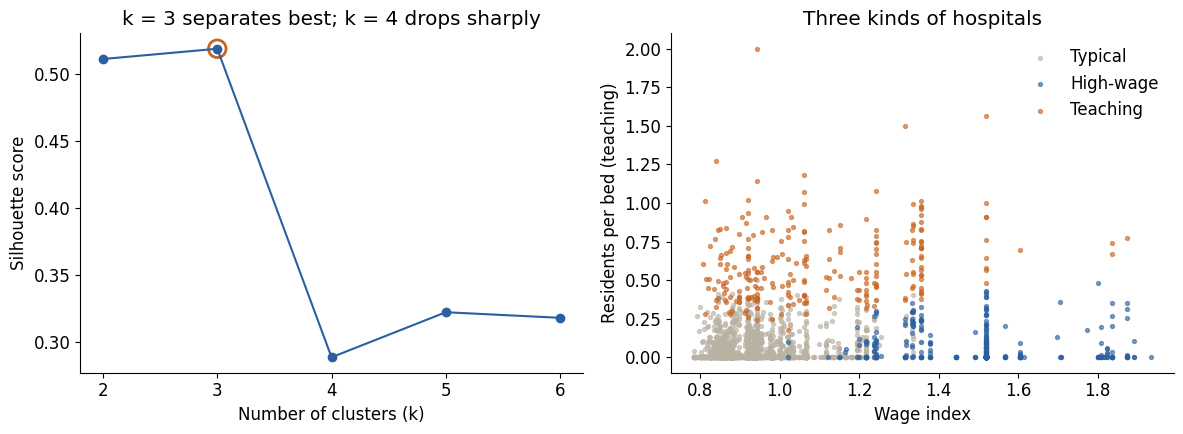

saved all 10 figures to /Volumes/workspace/cms/exports/figures


In [0]:
# 14j. Clusters: why k = 3, and what the groups look like
#      Why this chart: the silhouette line shows the k decision directly (peak at 3, sharp drop at 4), and the
#      scatter of wage vs teaching shows the three groups are real and nameable.
sil = [silhouette_score(Z, KMeans(n_clusters=k_, n_init=20, random_state=42).fit_predict(Z)) for k_ in range(2, 7)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(range(2, 7), sil, marker="o", color=BLUE); axes[0].scatter([3], [sil[1]], s=160, facecolors="none", edgecolors=ORANGE, lw=2); axes[0].set_xticks(range(2, 7)); axes[0].set_xlabel("Number of clusters (k)"); axes[0].set_ylabel("Silhouette score"); axes[0].set_title("k = 3 separates best; k = 4 drops sharply")
cmap = {"Typical": GREY, "High-wage": BLUE, "Teaching": ORANGE}; [axes[1].scatter(reg.loc[reg["cluster_name"] == c, "wage_index"], reg.loc[reg["cluster_name"] == c, "rbr"], s=8, alpha=0.6, color=col, label=c) for c, col in cmap.items()]
axes[1].set_xlabel("Wage index"); axes[1].set_ylabel("Residents per bed (teaching)"); axes[1].set_title("Three kinds of hospitals"); axes[1].legend(frameon=False); fig.tight_layout(); save(fig, "f10_clusters")
print("saved all 10 figures to", fig_dir)